In [ ]:
!pip install scikit-learn==1.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 95.3 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [ ]:
%pip install flask_cors

**MODELO FINAL - XGBoost**

In [ ]:
import pandas as pd
import numpy as np
import joblib
import json
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import backend as K

from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize
from imblearn.over_sampling import SMOTE

import xgboost as xgb

In [ ]:
SEED = 42
K.clear_session()
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

**Preprocesamiento**

In [ ]:
# ── Cargar datos ──────────────────────────────────────────
df = pd.read_csv("../data/data.csv", encoding="latin1", sep=";")

# ── Eliminar variables no disponibles en triaje ───────────
cols_eliminar = [
    "Group", "NRS_pain", "Diagnosis in ED", "Disposition",
    "KTAS_RN", "Error_group", "Length of stay_min",
    "KTAS duration_min", "mistriage"
]
df_modelo = df.drop(columns=cols_eliminar, errors="ignore")

# ── Limpieza numérica ─────────────────────────────────────
cols_clinicas = ["SBP", "DBP", "HR", "RR", "BT", "Saturation"]
for col in cols_clinicas:
    df_modelo[col] = df_modelo[col].astype(str).str.replace(',', '.').str.strip()
    df_modelo[col] = pd.to_numeric(df_modelo[col], errors='coerce')

df_modelo.loc[(df_modelo["Saturation"] < 50) | (df_modelo["Saturation"] > 100), "Saturation"] = np.nan

# ── Variables categóricas ─────────────────────────────────
df_modelo["Sex"]    = df_modelo["Sex"].replace({1: 1, 2: 0})
df_modelo["Injury"] = df_modelo["Injury"].replace({1: 0, 2: 1})

# ── Chief_complain → columnas binarias ────────────────────
def map_clinical_categories(text):
    text = str(text).lower()
    categorias = []
    if any(x in text for x in ['chest','palpitation','heart','cardiac']):
        categorias.append('Cardiovascular_Agudo')
    if any(x in text for x in ['dyspnea','breath','respiratory','chok']):
        categorias.append('Dificultad_Respiratoria')
    if any(x in text for x in ['weakness','hemiparesis','palsy','speech','dysarthria','numbness']):
        categorias.append('Neurologico_Ictus')
    if any(x in text for x in ['mental','confus','unconscious','syncope','seizure','drowsy']):
        categorias.append('Alteracion_Conciencia')
    if any(x in text for x in ['abd','epigastric','stomach','melena','hematemesis','vomit']):
        categorias.append('Abdominal_Grave')
    if any(x in text for x in ['headache','ha','dizziness','vertigo']):
        categorias.append('Cefalea_Mareo')
    if any(x in text for x in ['injury','trauma','wound','laceration','burn','fracture']):
        categorias.append('Trauma_Accidente')
    if any(x in text for x in ['fever','chill','f/c','infection']):
        categorias.append('Infeccioso_Fiebre')
    if len(categorias) == 0:
        categorias.append('Otros_Sintomas')
    return categorias

from sklearn.preprocessing import MultiLabelBinarizer
df_modelo['Chief_complain_Cat'] = df_modelo['Chief_complain'].apply(map_clinical_categories)
mlb = MultiLabelBinarizer()
df_motivos = pd.DataFrame(
    mlb.fit_transform(df_modelo['Chief_complain_Cat']),
    columns=mlb.classes_,
    index=df_modelo.index
)
df_modelo = df_modelo.drop(columns=["Chief_complain", "Chief_complain_Cat"], errors="ignore")

NameError: name 'pd' is not defined

**Dataset App Agrupacion 3 clases**

In [ ]:
# ── Features Dataset App (sin Arrival mode, sin Patients per hour) ──
X_C = df_modelo[[
    "Sex", "Age", "Injury", "Pain",
    "SBP", "DBP", "HR", "RR", "BT", "Saturation", "Mental"
]]
X_completo_C = pd.concat([
    X_C.reset_index(drop=True),
    df_motivos.reset_index(drop=True)
], axis=1)

# ── Agrupación 3 clases ───────────────────────────────────
# 1 = Crítico (KTAS 1+2) | 2 = Urgente (KTAS 3) | 3 = No urgente (KTAS 4+5)
mapa_clases = {1: 1, 2: 1, 3: 2, 4: 3, 5: 3}
y = df['KTAS_expert'].map(mapa_clases)

# ── Guardar el orden de columnas ──────────────────────────
feature_names = X_completo_C.columns.tolist()
print("Features del modelo:", feature_names)
print("Total:", len(feature_names))

# ── Split ─────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_completo_C, y, train_size=0.8, random_state=42, stratify=y
)
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, train_size=0.9, random_state=42, stratify=y_train
)

Features del modelo: ['Sex', 'Age', 'Injury', 'Pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'Mental', 'Abdominal_Grave', 'Alteracion_Conciencia', 'Cardiovascular_Agudo', 'Cefalea_Mareo', 'Dificultad_Respiratoria', 'Infeccioso_Fiebre', 'Neurologico_Ictus', 'Otros_Sintomas', 'Trauma_Accidente']
Total: 20


In [ ]:
# ── Imputación ────────────────────────────────────────────
imputer = IterativeImputer(random_state=42, max_iter=10)
X_train_imp = imputer.fit_transform(X_train_sub)
X_val_imp   = imputer.transform(X_val)
X_test_imp  = imputer.transform(X_test)

# ── Escalado ──────────────────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_final    = scaler.transform(X_val_imp)
X_test_final   = scaler.transform(X_test_imp)

# ── SMOTE (solo sobre train, nunca sobre val ni test) ─────
sm = SMOTE(random_state=42, k_neighbors=4)
X_train_final, y_train_res = sm.fit_resample(X_train_scaled, y_train_sub)

y_train_final_label = y_train_res
y_val_final_label   = y_val
y_test_final_label  = y_test

print("Train tras SMOTE:", X_train_final.shape)
print("Val:", X_val_final.shape)
print("Test:", X_test_final.shape)

Train tras SMOTE: (1152, 20)
Val: (102, 20)
Test: (254, 20)


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


**Entrenamiento XGBoost**

              precision    recall  f1-score   support

     Crítico       0.55      0.63      0.59        49
     Urgente       0.57      0.56      0.56        98
  No urgente       0.68      0.64      0.66       107

    accuracy                           0.61       254
   macro avg       0.60      0.61      0.61       254
weighted avg       0.61      0.61      0.61       254

F1 Macro:  0.606
Accuracy:  0.610


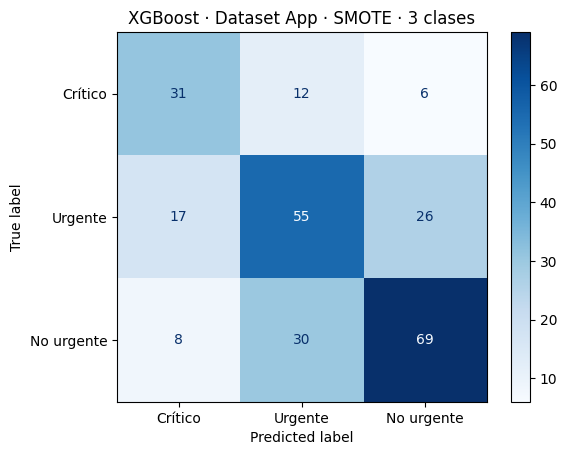

In [ ]:
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=44,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_final, y_train_final_label - 1,
    eval_set=[
        (X_train_final, y_train_final_label - 1),
        (X_val_final,   y_val_final_label   - 1)
    ],
    verbose=False
)

# ── Evaluación en test ────────────────────────────────────
y_pred_xgb  = xgb_model.predict(X_test_final) + 1
y_proba_xgb = xgb_model.predict_proba(X_test_final)

print(classification_report(y_test_final_label, y_pred_xgb,
      target_names=['Crítico','Urgente','No urgente']))
print(f"F1 Macro:  {f1_score(y_test_final_label, y_pred_xgb, average='macro'):.3f}")
print(f"Accuracy:  {accuracy_score(y_test_final_label, y_pred_xgb):.3f}")

# ── Matriz de confusión ───────────────────────────────────
cm = confusion_matrix(y_test_final_label, y_pred_xgb)
disp = ConfusionMatrixDisplay(cm, display_labels=['Crítico','Urgente','No urgente'])
disp.plot(cmap='Blues')
plt.title('XGBoost · Dataset App · SMOTE · 3 clases')
plt.show()

In [ ]:
# ── Guardar artefactos para Flask ─────────────────────────
joblib.dump(imputer, 'imputer.pkl')
joblib.dump(scaler,  'scaler.pkl')
xgb_model.save_model('xgb_model.json')

with open('feature_names.json', 'w') as f:
    json.dump(feature_names, f)

print("Archivos generados:")
print("  · imputer.pkl")
print("  · scaler.pkl")
print("  · xgb_model.json")
print("  · feature_names.json")

# ── Descarga desde Colab ──────────────────────────────────
from google.colab import files
files.download('imputer.pkl')
files.download('scaler.pkl')
files.download('xgb_model.json')
files.download('feature_names.json')

Archivos generados:
  · imputer.pkl
  · scaler.pkl
  · xgb_model.json
  · feature_names.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import flask, flask_cors, joblib, numpy, xgboost, sklearn

print("Flask:", flask.__version__)
print("Flask-CORS:", flask_cors.__version__)
print("Joblib:", joblib.__version__)
print("NumPy:", numpy.__version__)
print("XGBoost:", xgboost.__version__)
print("Scikit-learn:", sklearn.__version__)

Flask: 3.1.3
Flask-CORS: 6.0.5
Joblib: 1.6.0
NumPy: 2.1.3
XGBoost: 3.4.1
Scikit-learn: 1.9.0


/tmp/ipykernel_2260/1753104210.py:3: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask:", flask.__version__)


In [ ]:
import joblib, json, xgboost as xgb
imp = joblib.load('imputer.pkl'); sc = joblib.load('scaler.pkl')
m = xgb.XGBClassifier(); m.load_model('xgb_model.json')
fn = json.load(open('feature_names.json'))
print(imp.n_features_in_, sc.n_features_in_, m.n_features_in_, len(fn))
print(m.n_classes_)  # debe ser 3

20 20 20 20
3
